# Our approach (extension-based semantics) — DeepSeek-V3 on COM2SENSE (500 claims, sample hash 3d1fbba18f)

Facts, PRO/CON argument generation and selection, relation audit, bipolar framework construction, grounded / preferred / stable extensions and the four decision rules, extra statistics and example frameworks. Results: credulous 68.0, skeptical 77.0 (= majority = No-objection = grounded), net support 67.0, 41.8% of claims with more than one extension. The saved frameworks are in `results/per_claim/deepseek_com2sense_clean_500.pkl`.

Run on Kaggle; the API key is read from Kaggle secrets (`DEEPSEEK_API_KEY`). Outputs are kept so the reported numbers can be checked.

In [4]:
# ===== CELL 1: setup — DeepSeek + COM2SENSE (new sample) =====
!pip install -q openai datasets scikit-learn

import os, re, json, time, pickle, hashlib
from pathlib import Path
from itertools import combinations
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
from openai import OpenAI
from kaggle_secrets import UserSecretsClient
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
from IPython.display import FileLink, display

# ---- model + dataset ----
MODEL_NAME = "deepseek-chat"
LABEL      = "DeepSeek-V3"
DATASET    = "COM2SENSE"
RUN_NAME   = "deepseek_com2sense_clean"
WORKERS    = 4

WORK_DIR = Path("/kaggle/working") / RUN_NAME
WORK_DIR.mkdir(parents=True, exist_ok=True)
CKPT = WORK_DIR / f"{RUN_NAME}_ckpt.pkl"

key = UserSecretsClient().get_secret("DEEPSEEK_API_KEY")
client = OpenAI(api_key=key, base_url="https://api.deepseek.com", timeout=180)

# ---- COM2SENSE: balanced 500-claim sample (fixed seed) ----
C2S_REPO = "/kaggle/working/Com2Sense"
if not Path(C2S_REPO).exists():
    os.system(f"git clone -q --depth 1 https://github.com/PlusLabNLP/Com2Sense.git {C2S_REPO}")
raw = pd.DataFrame(json.load(open(f"{C2S_REPO}/data/train.json")))
raw = raw[raw["label"].isin(["True", "False"])].copy()
raw["gold"] = (raw["label"] == "True").astype(int)
raw = raw.sort_values("id").reset_index(drop=True)      # fixed order before sampling

SEED = 42
true_part  = raw[raw["gold"] == 1].sample(n=250, random_state=SEED)
false_part = raw[raw["gold"] == 0].sample(n=250, random_state=SEED)
sample = pd.concat([true_part, false_part]).sample(frac=1, random_state=SEED).reset_index(drop=True)

baf_df = pd.DataFrame({
    "example_index": range(len(sample)),
    "claim": sample["sent"].astype(str).str.strip(),
    "facts_text": "",                                    # COM2SENSE has no facts
    "gold": sample["gold"].astype(int),
    "source_id": sample["id"],
})
SAMPLE_HASH = hashlib.md5("|".join(baf_df["source_id"]).encode()).hexdigest()[:10]
print("COM2SENSE train statements:", len(raw), "| sample:", len(baf_df),
      "| true:", int(baf_df["gold"].sum()), "| SAMPLE HASH:", SAMPLE_HASH)
print("first claim:", baf_df.iloc[0]["claim"])
baf_df.to_csv("/kaggle/working/com2sense_sample_500.csv", index=False)

# ---- API test ----
r = client.chat.completions.create(
    model=MODEL_NAME, temperature=0, max_tokens=10,
    messages=[{"role": "user",
               "content": "Is Paris in France? Answer true or false."}])
print("API test:", r.choices[0].message.content)

COM2SENSE train statements: 1608 | sample: 500 | true: 250 | SAMPLE HASH: 3d1fbba18f
first claim: If Mary does a bad job at cutting my hair, I will be likely to make a return appointment.
API test: True.


In [5]:
# ===== CELL 2: argument generation + selection (unchanged) =====
BAF_CONFIG = {
    "n_pro_candidates": 5, "n_con_candidates": 5,
    "max_pro_keep": 4, "max_con_keep": 4,
    "min_relevance": 0.60, "min_grounding": 0.55,
    "min_clarity": 0.60, "min_quality": 0.58,
    "min_target_match": 0.65, "min_grounding_edge": 0.55,
    "min_relation_score": 0.68,
    "max_conflict_pairs": 3, "max_claim_attacks": 2,
    "audit_batch_size": 16,
    "generation_temperature": 0.15, "audit_temperature": 0.0,
    "max_retries": 5,
}

SYSTEM = ("You are an expert in claim verification, formal "
          "argumentation and strict JSON output.")


def clip01(v):
    try:
        return max(0.0, min(1.0, float(v)))
    except Exception:
        return 0.0


def extract_json_object(text):
    text = str(text or "").strip()
    text = re.sub(r"```(?:json)?", "", text, flags=re.IGNORECASE)
    text = text.strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass
    s, e = text.find("{"), text.rfind("}")
    if s >= 0 and e > s:
        return json.loads(text[s:e + 1])
    raise ValueError("No JSON")


def json_call(prompt, temperature, max_tokens, retries=8):
    last = None
    for a in range(1, retries + 1):
        try:
            resp = client.chat.completions.create(
                model=MODEL_NAME,
                messages=[{"role": "system", "content": SYSTEM},
                          {"role": "user", "content": prompt}],
                temperature=temperature, max_tokens=max_tokens)
            t = resp.choices[0].message.content
            if not t:
                raise ValueError("empty")
            return extract_json_object(t)
        except Exception as e:
            last = e
            msg = str(e)
            if "402" in msg:
                raise RuntimeError("no API credit left")
            busy = any(c in msg for c in ["429", "502", "503", "504"])
            if busy or "rate" in msg.lower():
                time.sleep(20 * a)
            else:
                time.sleep(3 * a)
    raise RuntimeError(f"failed: {last}")


def generate_and_score_arguments(claim, facts_text, config=BAF_CONFIG):
    prompt = f"""
Construct candidate arguments for a Bipolar Argumentation Framework used for claim verification.

CLAIM:
{claim}

AVAILABLE FACTS:
{facts_text}

First determine the intended meaning of the claim, then reason carefully from facts and commonsense.

Generate up to {config["n_pro_candidates"]} PRO candidates and up to {config["n_con_candidates"]} CON candidates.

PRO: a specific, grounded reason the claim is TRUE.
CON: a specific, grounded reason the claim is FALSE.

CRITICAL rules for CON arguments (attacks):
- Only generate a CON if there is a GENUINE, SPECIFIC, STRONG reason the claim is false.
- Do NOT generate speculative CONs like "maybe not always", "it might not", "in some cases".
- Do NOT generate a CON that merely raises a weak possibility; it must give a real reason the claim is false.
- If the claim is clearly true and there is no strong objection, generate ZERO CON arguments.

CRITICAL rules for PRO arguments:
- Only generate a PRO if there is genuine support. If the claim is clearly false, generate ZERO PRO arguments.
- Do NOT generate circular or vague arguments.

General:
- Each argument must be specific and grounded, under 30 words.
- Do not output the final TRUE/FALSE label.

Score each candidate 0 to 1 for: relevance; grounding; clarity; overall_quality.
Score speculative, weak, vague, or circular arguments BELOW 0.4 on overall_quality.

Return valid JSON only:
{{
  "interpreted_claim": "brief meaning",
  "pro": [{{"text":"...","relevance":0.0,"grounding":0.0,"clarity":0.0,"overall_quality":0.0}}],
  "con": [{{"text":"...","relevance":0.0,"grounding":0.0,"clarity":0.0,"overall_quality":0.0}}]
}}
""".strip()
    raw = json_call(prompt, config["generation_temperature"], 1900,
                    config["max_retries"])
    out = {"interpreted_claim":
           str(raw.get("interpreted_claim", "")).strip(),
           "pro": [], "con": []}
    for role in ("pro", "con"):
        items = raw.get(role, [])
        if not isinstance(items, list):
            items = []
        for e in items:
            if not isinstance(e, dict):
                continue
            t = str(e.get("text", "")).strip()
            if not t:
                continue
            out[role].append({
                "text": t,
                "relevance": clip01(e.get("relevance")),
                "grounding": clip01(e.get("grounding")),
                "clarity": clip01(e.get("clarity")),
                "overall_quality": clip01(e.get("overall_quality"))})
    return out


def select_arguments(gen, config=BAF_CONFIG):
    nodes = {"CLAIM": {"role": "CLAIM", "text": ""}}
    scored = []
    plan = [("pro", "PRO", "P", config["max_pro_keep"]),
            ("con", "CON", "N", config["max_con_keep"])]
    for src, role, pre, mx in plan:
        cands = []
        for it in gen.get(src, []):
            rl = clip01(it.get("relevance"))
            g = clip01(it.get("grounding"))
            cl = clip01(it.get("clarity"))
            q = clip01(it.get("overall_quality"))
            rank = 0.30 * rl + 0.30 * g + 0.15 * cl + 0.25 * q
            sc = {**it, "role": role, "rank_score": rank}
            scored.append(sc)
            ok = (rl >= config["min_relevance"]
                  and g >= config["min_grounding"]
                  and cl >= config["min_clarity"]
                  and q >= config["min_quality"])
            if ok:
                cands.append(sc)
        cands.sort(key=lambda x: x["rank_score"], reverse=True)
        for n, it in enumerate(cands[:mx], 1):
            nodes[f"{pre}{n}"] = {
                "role": role, "text": it["text"],
                "relevance": it["relevance"],
                "grounding": it["grounding"],
                "clarity": it["clarity"],
                "overall_quality": it["overall_quality"],
                "rank_score": it["rank_score"]}
    return {"nodes": nodes, "all_scored": scored}


def build_relation_candidates(nodes):
    pro = [n for n, i in nodes.items() if i["role"] == "PRO"]
    con = [n for n, i in nodes.items() if i["role"] == "CON"]
    c = []
    for p in pro:
        c.append({"source": p, "target": "CLAIM",
                  "allowed": ["SUPPORT", "NONE"]})
    for n in con:
        c.append({"source": n, "target": "CLAIM",
                  "allowed": ["ATTACK", "NONE"]})
    for p in pro:
        for n in con:
            c.append({"source": p, "target": n,
                      "allowed": ["ATTACK", "NONE"]})
            c.append({"source": n, "target": p,
                      "allowed": ["ATTACK", "NONE"]})
    return c


print("Cell 2 ready: generation + selection")

Cell 2 ready: generation + selection


In [6]:
# ===== CELL 3: relation audit + framework construction (unchanged) =====
def audit_baf_relations(claim, facts_text, nodes, config=BAF_CONFIG,
                        batch_size=16):
    cands = build_relation_candidates(nodes)
    at = "\n".join(f"{nid} [{i['role']}]: {i['text']}"
                   for nid, i in nodes.items() if nid != "CLAIM")
    aud = []
    for bs in range(0, len(cands), batch_size):
        b = cands[bs:bs + batch_size]
        pb = "\n".join(f"{it['source']} -> {it['target']} | "
                       f"allowed={it['allowed']}" for it in b)
        prompt = f"""Audit candidate relations for a Bipolar Argumentation Framework.

CLAIM:
{claim}
FACTS:
{facts_text}
ARGUMENTS:
{at}

For every candidate, choose exactly one allowed type.
SUPPORT: source gives a meaningful direct reason to accept target.
ATTACK: source directly contradicts, rebuts or undermines target.
NONE: no meaningful direct relation.
Use ATTACK for CON->CLAIM only if the CON gives a genuine reason the claim is false or doubtful.
Use NONE when the CON concedes the claim or agrees.
Keep every reason at eight words or fewer.
For ATTACK/SUPPORT scores normally exceed 0.50; for NONE normally below 0.50.

CANDIDATES:
{pb}

Return valid JSON only:
{{"relations":[{{"source":"P1","target":"CLAIM","type":"SUPPORT","target_match":0.9,"grounding":0.9,"relation_score":0.9,"reason":"..."}}]}}"""
        raw = json_call(prompt, config["audit_temperature"], 2200,
                        config["max_retries"])
        exp = {(it["source"], it["target"]) for it in b}
        allow = {(it["source"], it["target"]): set(it["allowed"])
                 for it in b}
        ret = {}
        rels = raw.get("relations", [])
        if not isinstance(rels, list):
            rels = []
        for r in rels:
            if not isinstance(r, dict):
                continue
            s = str(r.get("source", "")).strip()
            t = str(r.get("target", "")).strip()
            typ = str(r.get("type", "NONE")).strip().upper()
            pr = (s, t)
            if pr not in exp or typ not in allow[pr]:
                continue
            ret[pr] = {"source": s, "target": t, "type": typ,
                       "target_match": clip01(r.get("target_match")),
                       "grounding": clip01(r.get("grounding")),
                       "relation_score": clip01(r.get("relation_score")),
                       "reason": str(r.get("reason", "")).strip()}
        for it in b:
            pr = (it["source"], it["target"])
            if pr not in ret:
                ret[pr] = {"source": pr[0], "target": pr[1],
                           "type": "NONE", "target_match": 0.0,
                           "grounding": 0.0, "relation_score": 0.0,
                           "reason": "omitted"}
        aud.extend(ret.values())
    return {"all_audited_relations": aud}


def relation_passes(r, config=BAF_CONFIG):
    return (r["target_match"] >= config["min_target_match"]
            and r["grounding"] >= config["min_grounding_edge"]
            and r["relation_score"] >= config["min_relation_score"])


def relation_lookup(rels):
    return {(r["source"], r["target"]): r for r in rels}


def select_formal_supports(rels, config=BAF_CONFIG):
    return sorted(set(
        (r["source"], r["target"]) for r in rels
        if r["type"] == "SUPPORT" and r["target"] == "CLAIM"
        and r["source"].startswith("P") and relation_passes(r, config)))


def select_con_claim_attacks(rels, config=BAF_CONFIG):
    p = [r for r in rels
         if r["type"] == "ATTACK" and r["target"] == "CLAIM"
         and r["source"].startswith("N") and relation_passes(r, config)]
    p.sort(key=lambda x: x["relation_score"], reverse=True)
    return p[:config["max_claim_attacks"]]


def select_independent_conflict_pairs(rels, config=BAF_CONFIG):
    lk = relation_lookup(rels)
    cand = []
    pro = sorted({r["source"] for r in rels
                  if r["source"].startswith("P")})
    con = sorted({r["source"] for r in rels
                  if r["source"].startswith("N")})
    for p in pro:
        for n in con:
            pc, cp = lk.get((p, n)), lk.get((n, p))
            if not pc or not cp:
                continue
            if (pc["type"] == "ATTACK" and cp["type"] == "ATTACK"
                    and relation_passes(pc, config)
                    and relation_passes(cp, config)):
                cand.append({"pro": p, "con": n,
                             "pair_score": min(pc["relation_score"],
                                               cp["relation_score"])})
    cand.sort(key=lambda x: x["pair_score"], reverse=True)
    sel, up, uc = [], set(), set()
    for c in cand:
        if c["pro"] in up or c["con"] in uc:
            continue
        sel.append(c)
        up.add(c["pro"])
        uc.add(c["con"])
        if len(sel) >= config["max_conflict_pairs"]:
            break
    return sel, cand


def support_closure(nodes, sup):
    cl = set(sup)
    ch = True
    while ch:
        ch = False
        new = set()
        for a, b in cl:
            for c, d in cl:
                if b == c and (a, d) not in cl:
                    new.add((a, d))
        if new:
            cl |= new
            ch = True
    return cl


def derive_attacks(nodes, direct, sup):
    sc = support_closure(nodes, sup)
    sa, se = set(), set()
    for s, sd in sc:
        for at, t in direct:
            if sd == at:
                sa.add((s, t))
    for at, ad in direct:
        for s, sd in sc:
            if ad == s:
                se.add((at, sd))
    eff = {e for e in (set(direct) | sa | se) if e[0] != e[1]}
    return {"support_closure": sorted(sc),
            "supported_attacks": sorted(sa),
            "secondary_attacks": sorted(se),
            "effective_attacks": sorted(eff)}


print("Cell 3 ready: audit + framework construction")

Cell 3 ready: audit + framework construction


In [7]:
# ===== CELL 4: semantics + decision rules (CORRECTED) =====
def all_subsets(items):
    il = sorted(items)
    for sz in range(len(il) + 1):
        for sub in combinations(il, sz):
            yield set(sub)


def cf(e, att):
    return not any(s in e and t in e for s, t in att)


def att_of(a, att):
    return {s for s, t in att if t == a}


def ext_att(e, a, att):
    return any(s in e and t == a for s, t in att)


def defends(e, a, att):
    return all(ext_att(e, x, att) for x in att_of(a, att))


def admissible(e, att):
    return cf(e, att) and all(defends(e, a, att) for a in e)


def preferred_ext(args, att):
    adm = [s for s in all_subsets(args) if admissible(s, att)]
    return [c for c in adm if not any(c < o for o in adm)]


def stable_ext(args, att):
    return [c for c in all_subsets(args)
            if cf(c, att) and all(ext_att(c, a, att) for a in args - c)]


def grounded_ext(args, att):
    g = set()
    while True:
        new = {a for a in args if defends(g, a, att)}
        if new == g:
            return g
        g = new


def claim_attackers(att, cid="CLAIM"):
    # ALL attackers of the claim: direct CON->CLAIM + secondary attacks
    return {s for s, t in att if t == cid}


def decide(exts, att, cid="CLAIM"):
    """Four extension-based rules. att = effective (final) attack relation."""
    exts = [set(e) for e in exts]
    if not exts:
        return {"credulous": 0, "skeptical": 0,
                "majority": 0, "no_objection": 0}
    cc = sum(cid in e for e in exts)
    in_some = set().union(*exts)
    return {
        "credulous":    int(cc >= 1),
        "skeptical":    int(cc == len(exts)),
        "majority":     int(cc * 2 > len(exts)),          # STRICT majority
        "no_objection": int(cc >= 1 and not (claim_attackers(att, cid) & in_some)),
    }


def rebuild(inter, config=BAF_CONFIG):
    nodes = dict(inter["nodes"])
    rels = inter["all_audited_relations"]
    sup = set(select_formal_supports(rels, config))
    sca = select_con_claim_attacks(rels, config)
    sp, _ = select_independent_conflict_pairs(rels, config)
    direct = set()
    for r in sca:
        direct.add((r["source"], r["target"]))
    for p in sp:
        direct.add((p["pro"], p["con"]))
        direct.add((p["con"], p["pro"]))
    conn = {"CLAIM"}
    for st in sup | direct:
        conn.add(st[0])
        conn.add(st[1])
    nodes = {k: v for k, v in nodes.items() if k in conn}
    vids = set(nodes)
    sup = {e for e in sup if e[0] in vids and e[1] in vids}
    direct = {e for e in direct if e[0] in vids and e[1] in vids}
    der = derive_attacks(vids, direct, sup)
    eff = set(map(tuple, der["effective_attacks"]))
    pref = preferred_ext(vids, eff)
    stab = stable_ext(vids, eff)
    grd = grounded_ext(vids, eff)
    pairs = [{"pro": p["pro"], "con": p["con"],
              "pair_score": p["pair_score"]} for p in sp]
    return {**inter, "nodes": nodes, "supports": sorted(sup),
            "selected_claim_attacks": sca,
            "selected_conflict_pairs": pairs,
            "direct_attacks": sorted(direct),
            "support_closure": der["support_closure"],
            "supported_attacks": der["supported_attacks"],
            "secondary_attacks": der["secondary_attacks"],
            "effective_attacks": der["effective_attacks"],
            "preferred_extensions": [sorted(e) for e in pref],
            "stable_extensions": [sorted(e) for e in stab],
            "grounded_extension": sorted(grd)}


def run_example(row, config=BAF_CONFIG):
    claim = str(row["claim"]).strip()
    facts = str(row["facts_text"]).strip()
    gold = int(row["gold"])
    gen = generate_and_score_arguments(claim, facts, config)
    sel = select_arguments(gen, config)
    nodes = sel["nodes"]
    nodes["CLAIM"]["text"] = claim
    audit = audit_baf_relations(claim, facts, nodes, config,
                                config["audit_batch_size"])
    inter = {"example_index": int(row["example_index"]),
             "claim": claim, "facts_text": facts, "gold": gold,
             "interpreted_claim": gen["interpreted_claim"],
             "generated_arguments": gen,
             "argument_scores": sel["all_scored"],
             "nodes": nodes,
             "all_audited_relations": audit["all_audited_relations"],
             "model": MODEL_NAME, "pipeline_version": "v2-clean",
             "config": dict(config)}
    return rebuild(inter, config)


# --- unit tests on toy frameworks (no API call) ---
att = {("P1", "N1"), ("N1", "P1"), ("N1", "CLAIM")}
args = {"CLAIM", "P1", "N1"}
ex = preferred_ext(args, att)
assert len(ex) == 2
assert decide(ex, att) == {"credulous": 1, "skeptical": 0,
                           "majority": 0, "no_objection": 0}
assert "CLAIM" not in grounded_ext(args, att)
assert decide(preferred_ext({"CLAIM", "P1"}, set()), set()) == \
    {"credulous": 1, "skeptical": 1, "majority": 1, "no_objection": 1}
print("Cell 4 ready: semantics OK, unit tests passed")

test = run_example(baf_df.iloc[0])
print("one-example test | gold", test["gold"],
      "| nodes", len(test["nodes"]),
      "| extensions", len(test["preferred_extensions"]))

Cell 4 ready: semantics OK, unit tests passed
one-example test | gold 0 | nodes 6 | extensions 4


In [8]:
# ===== CELL 5: run all claims (with checkpoint, resumable) =====
def load_ck():
    return pickle.load(open(CKPT, "rb")) if CKPT.exists() else {}


def save_ck(d):
    tmp = CKPT.with_suffix(".tmp")
    pickle.dump(d, open(tmp, "wb"))
    tmp.replace(CKPT)


def safe_one(i):
    try:
        return i, run_example(baf_df.iloc[i]), None
    except Exception as e:
        return i, None, str(e)[:80]


def run_pass(label):
    d = load_ck()
    todo = [i for i in range(len(baf_df)) if i not in d]
    print(f"[{label}] have {len(d)}/{len(baf_df)}, running {len(todo)}",
          flush=True)
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        futs = [pool.submit(safe_one, i) for i in todo]
        for f in as_completed(futs):
            i, v, err = f.result()
            if err:
                print(f"  error at {i}: {err}", flush=True)
                continue
            d[i] = v
            save_ck(d)
            if len(d) % 25 == 0:
                print(f"  {len(d)}/{len(baf_df)} | "
                      f"{(time.time() - t0) / 60:.0f} min", flush=True)
    return load_ck()


d = run_pass("main run")
for k in range(2):
    if len(d) < len(baf_df):
        time.sleep(30)
        d = run_pass(f"retry {k + 1}")
print("done:", len(d), "claims")

[main run] have 0/500, running 500
  25/500 | 1 min
  50/500 | 1 min
  75/500 | 2 min
  100/500 | 2 min
  125/500 | 3 min
  150/500 | 3 min
  175/500 | 4 min
  200/500 | 4 min
  225/500 | 5 min
  250/500 | 5 min
  275/500 | 6 min
  300/500 | 6 min
  325/500 | 7 min
  350/500 | 7 min
  375/500 | 8 min
  400/500 | 8 min
  425/500 | 9 min
  450/500 | 10 min
  475/500 | 10 min
  500/500 | 11 min
done: 500 claims


In [9]:
# ===== CELL 6: results (all rules recomputed here) =====
d = load_ck()
results = [d[k] for k in sorted(d)]
gold = [r["gold"] for r in results]
n = len(results)


def metrics_row(name, pred):
    tn, fp, fn, tp = confusion_matrix(gold, pred, labels=[0, 1]).ravel()
    return {"method": name, "n": n,
            "acc": round(accuracy_score(gold, pred) * 100, 1),
            "prec": round(precision_score(gold, pred, zero_division=0) * 100, 1),
            "rec": round(recall_score(gold, pred, zero_division=0) * 100, 1),
            "f1": round(f1_score(gold, pred, zero_division=0) * 100, 1),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}


def net_support_pred(r):
    n_att = len(claim_attackers(set(map(tuple, r["effective_attacks"]))))
    return int(len(r["supports"]) >= n_att)


preds = {}
for r in results:
    att = set(map(tuple, r["effective_attacks"]))
    for sem in ["preferred", "stable"]:
        for rule, v in decide(r[f"{sem}_extensions"], att).items():
            preds.setdefault(f"{sem}_{rule}", []).append(v)
    preds.setdefault("grounded", []).append(int("CLAIM" in r["grounded_extension"]))
    preds.setdefault("net_support", []).append(net_support_pred(r))

order = [f"{s}_{x}" for s in ["preferred", "stable"]
         for x in ["credulous", "skeptical", "majority", "no_objection"]]
order += ["grounded", "net_support"]
table = pd.DataFrame([metrics_row(m, preds[m]) for m in order])
pd.set_option("display.width", 220)
print(f"=== {LABEL} | {DATASET} | clean run ({n} claims) | sample {SAMPLE_HASH} ===\n")
print(table.to_string(index=False))

# ---- extensions ----
n_ext = [len(r["preferred_extensions"]) for r in results]
cnt = Counter(n_ext)
multi = sum(k > 1 for k in n_ext)
print("\nextension counts:", dict(sorted(cnt.items())))
print("mean extensions:", round(float(np.mean(n_ext)), 2))
print(f"more than 1 extension: {multi} ({multi / n * 100:.1f}%)")
ext_rows = []
for k in sorted(cnt):
    idx = [i for i, e in enumerate(n_ext) if e == k]
    ext_rows.append({
        "n_ext": k, "claims": len(idx),
        "percent": round(len(idx) / n * 100, 1),
        "credulous_acc": round(np.mean([preds["preferred_credulous"][i] == gold[i] for i in idx]) * 100, 1),
        "skeptical_acc": round(np.mean([preds["preferred_skeptical"][i] == gold[i] for i in idx]) * 100, 1)})
print(pd.DataFrame(ext_rows).to_string(index=False))
print("failed claims:", len(baf_df) - n)

# ---- SANITY CHECKS (must all pass) ----
print("\n=== sanity checks ===")
same = ["preferred_skeptical", "preferred_majority", "preferred_no_objection",
        "stable_skeptical", "stable_majority", "stable_no_objection", "grounded"]
bad = [i for i in range(n) if len({preds[m][i] for m in same}) > 1]
print("1) skeptical = majority = no-objection = grounded :",
      "OK" if not bad else f"FAIL on {len(bad)} claims")
for i in bad[:5]:
    print("   ", results[i]["example_index"], {m: preds[m][i] for m in same},
          results[i]["effective_attacks"])
diff = sum(preds["preferred_credulous"][i] != preds["stable_credulous"][i] for i in range(n))
print("2) preferred = stable                              :",
      "OK" if diff == 0 else f"FAIL on {diff} claims")
odd = [k for k in cnt if k not in (1, 2, 4, 8)]
print("3) extension counts are 1, 2, 4 or 8               :",
      "OK" if not odd else f"FAIL {odd}")

# ---- save ----
os.chdir("/kaggle/working")
pickle.dump(results, open(f"{RUN_NAME}_{n}.pkl", "wb"))
table.to_csv(f"{RUN_NAME}_results.csv", index=False)
pd.DataFrame(ext_rows).to_csv(f"{RUN_NAME}_extensions.csv", index=False)
display(FileLink(f"{RUN_NAME}_results.csv"))

=== DeepSeek-V3 | COM2SENSE | clean run (500 claims) | sample 3d1fbba18f ===

                method   n  acc  prec  rec   f1  TN  FP  FN  TP
   preferred_credulous 500 68.0  63.2 86.4 73.0 124 126  34 216
   preferred_skeptical 500 77.0  83.9 66.8 74.4 218  32  83 167
    preferred_majority 500 77.0  83.9 66.8 74.4 218  32  83 167
preferred_no_objection 500 77.0  83.9 66.8 74.4 218  32  83 167
      stable_credulous 500 68.0  63.2 86.4 73.0 124 126  34 216
      stable_skeptical 500 77.0  83.9 66.8 74.4 218  32  83 167
       stable_majority 500 77.0  83.9 66.8 74.4 218  32  83 167
   stable_no_objection 500 77.0  83.9 66.8 74.4 218  32  83 167
              grounded 500 77.0  83.9 66.8 74.4 218  32  83 167
           net_support 500 67.0  60.6 97.2 74.7  92 158   7 243

extension counts: {1: 291, 2: 51, 4: 102, 8: 56}
mean extensions: 2.5
more than 1 extension: 209 (41.8%)
 n_ext  claims  percent  credulous_acc  skeptical_acc
     1     291     58.2           84.9           84.9
    

/kaggle/working/deepseek_com2sense_clean_results.csv

In [12]:
# ===== CELL 9: extra numbers for the paper (no API calls) =====
import time
from statsmodels.stats.contingency_tables import mcnemar

print(f"=== {LABEL} | {DATASET} | extra statistics ({n} claims) ===")

# ---- 1) Agreement with grounded ----
print("\n1) Agreement with grounded semantics")
agree_rows = []
for m in ["preferred_credulous", "preferred_skeptical",
          "preferred_majority", "preferred_no_objection"]:
    agree = np.mean([preds[m][i] == preds["grounded"][i] for i in range(n)])
    acc = np.mean([preds[m][i] == gold[i] for i in range(n)])
    agree_rows.append({"rule": m.replace("preferred_", ""),
                       "agreement_with_grounded_%": round(agree * 100, 1),
                       "accuracy_%": round(acc * 100, 1)})
agree_rows.append({"rule": "grounded", "agreement_with_grounded_%": 100.0,
                   "accuracy_%": round(np.mean([preds["grounded"][i] == gold[i]
                                                for i in range(n)]) * 100, 1)})
agree_df = pd.DataFrame(agree_rows)
print(agree_df.to_string(index=False))

# ---- 2) McNemar: credulous vs skeptical ----
print("\n2) McNemar test: credulous vs skeptical")
c_ok = [preds["preferred_credulous"][i] == gold[i] for i in range(n)]
s_ok = [preds["preferred_skeptical"][i] == gold[i] for i in range(n)]
b = sum(c and not s for c, s in zip(c_ok, s_ok))
c = sum(s and not c_ for c_, s in zip(c_ok, s_ok))
print(f"   claims where the two rules disagree: {b + c}")
print(f"   credulous right / skeptical wrong : {b}")
print(f"   skeptical right / credulous wrong : {c}")
if b + c == 0:
    print("   no disagreement -> test not applicable")
else:
    exact = (b + c) < 25
    res = mcnemar([[0, b], [c, 0]], exact=exact, correction=not exact)
    kind = "exact binomial" if exact else "chi-square with continuity correction"
    print(f"   McNemar ({kind}): statistic = {res.statistic:.2f}, p = {res.pvalue:.3f}")

# ---- 3) Runtime ----
print("\n3) Runtime of extension computation per claim")
times = []
for r in results:
    args = set(r["nodes"])
    att = set(map(tuple, r["effective_attacks"]))
    t0 = time.perf_counter()
    pe = preferred_ext(args, att)
    se = stable_ext(args, att)
    ge = grounded_ext(args, att)
    decide(pe, att)
    times.append((time.perf_counter() - t0) * 1000)
times = np.array(times)
print(f"   mean {times.mean():.2f} ms | median {np.median(times):.2f} ms | "
      f"max {times.max():.2f} ms | total {times.sum() / 1000:.2f} s")

# ---- 4) Framework size and edges ----
print("\n4) Framework size and edges (mean per claim, and % of claims with >= 1)")
def stats(vals):
    vals = np.array(vals)
    return round(vals.mean(), 2), round((vals > 0).mean() * 100, 1), int(vals.max())
size = {
    "arguments (without claim)": [len(r["nodes"]) - 1 for r in results],
    "PRO arguments": [sum(k.startswith("P") for k in r["nodes"]) for r in results],
    "CON arguments": [sum(k.startswith("N") for k in r["nodes"]) for r in results],
    "support edges (PRO->CLAIM)": [len(r["supports"]) for r in results],
    "direct attacks CON->CLAIM": [len(r["selected_claim_attacks"]) for r in results],
    "conflict pairs": [len(r["selected_conflict_pairs"]) for r in results],
    "secondary attacks": [len(r["secondary_attacks"]) for r in results],
    "all attackers of the claim": [len(claim_attackers(set(map(tuple, r["effective_attacks"]))))
                                   for r in results],
}
size_df = pd.DataFrame([{"item": k, "mean": stats(v)[0], "% claims >=1": stats(v)[1],
                         "max": stats(v)[2]} for k, v in size.items()])
print(size_df.to_string(index=False))
empty = sum(len(r["nodes"]) == 1 for r in results)
print(f"   frameworks with only the claim (no argument kept): {empty} ({empty / n * 100:.1f}%)")

agree_df.to_csv(f"/kaggle/working/{RUN_NAME}_agreement.csv", index=False)
size_df.to_csv(f"/kaggle/working/{RUN_NAME}_framework_size.csv", index=False)
print("\nsaved agreement + framework-size CSVs")

=== DeepSeek-V3 | COM2SENSE | extra statistics (500 claims) ===

1) Agreement with grounded semantics
        rule  agreement_with_grounded_%  accuracy_%
   credulous                       71.4        68.0
   skeptical                      100.0        77.0
    majority                      100.0        77.0
no_objection                      100.0        77.0
    grounded                      100.0        77.0

2) McNemar test: credulous vs skeptical
   claims where the two rules disagree: 143
   credulous right / skeptical wrong : 49
   skeptical right / credulous wrong : 94
   McNemar (chi-square with continuity correction): statistic = 13.54, p = 0.000

3) Runtime of extension computation per claim
   mean 0.41 ms | median 0.26 ms | max 3.68 ms | total 0.20 s

4) Framework size and edges (mean per claim, and % of claims with >= 1)
                      item  mean  % claims >=1  max
 arguments (without claim)  3.98          96.8    8
             PRO arguments  2.64          80.4    

01_claim_only  (16 claims in this situation)


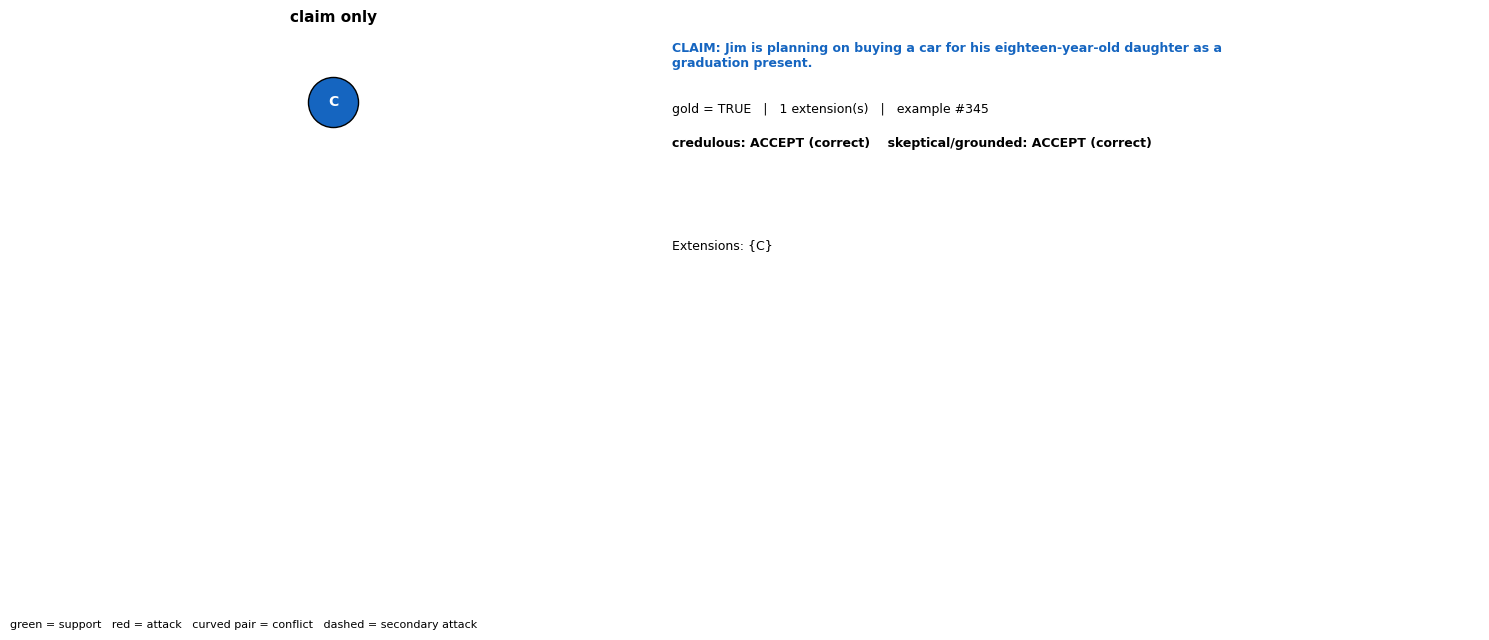

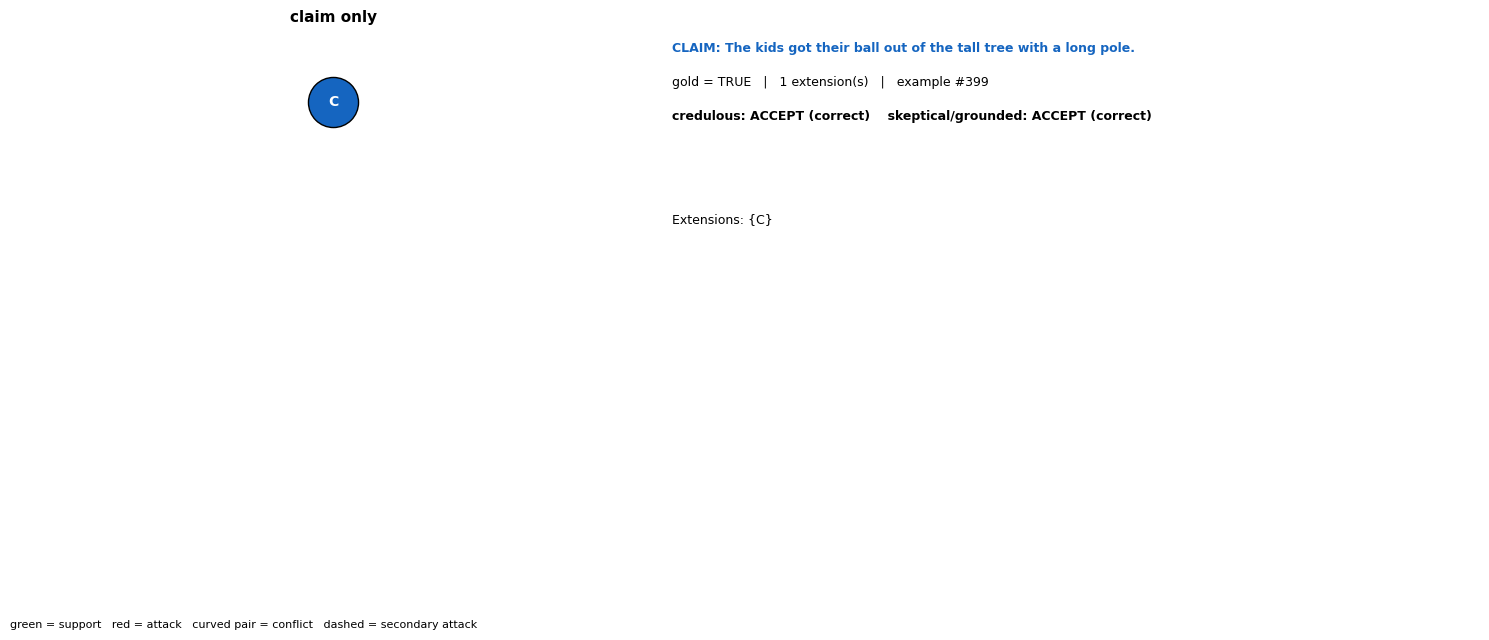

02_pro_only_correct  (158 claims in this situation)


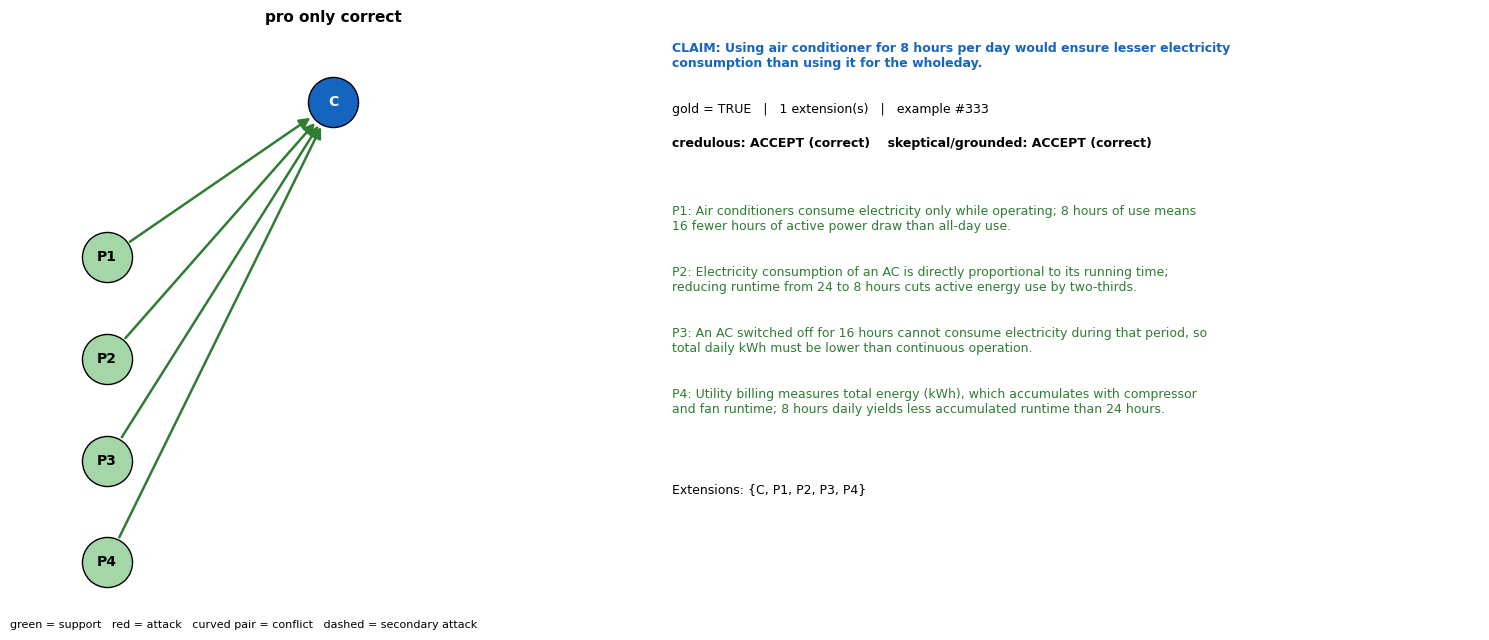

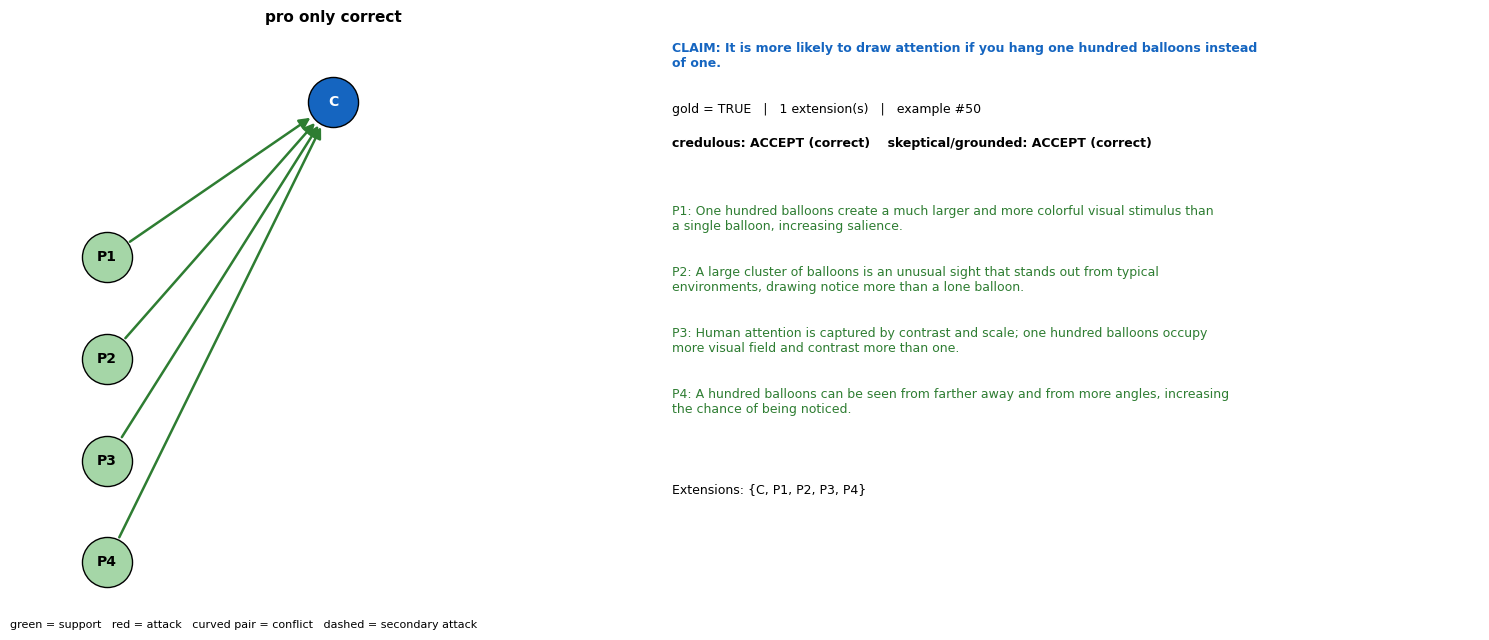

03_pro_only_WRONG  (25 claims in this situation)


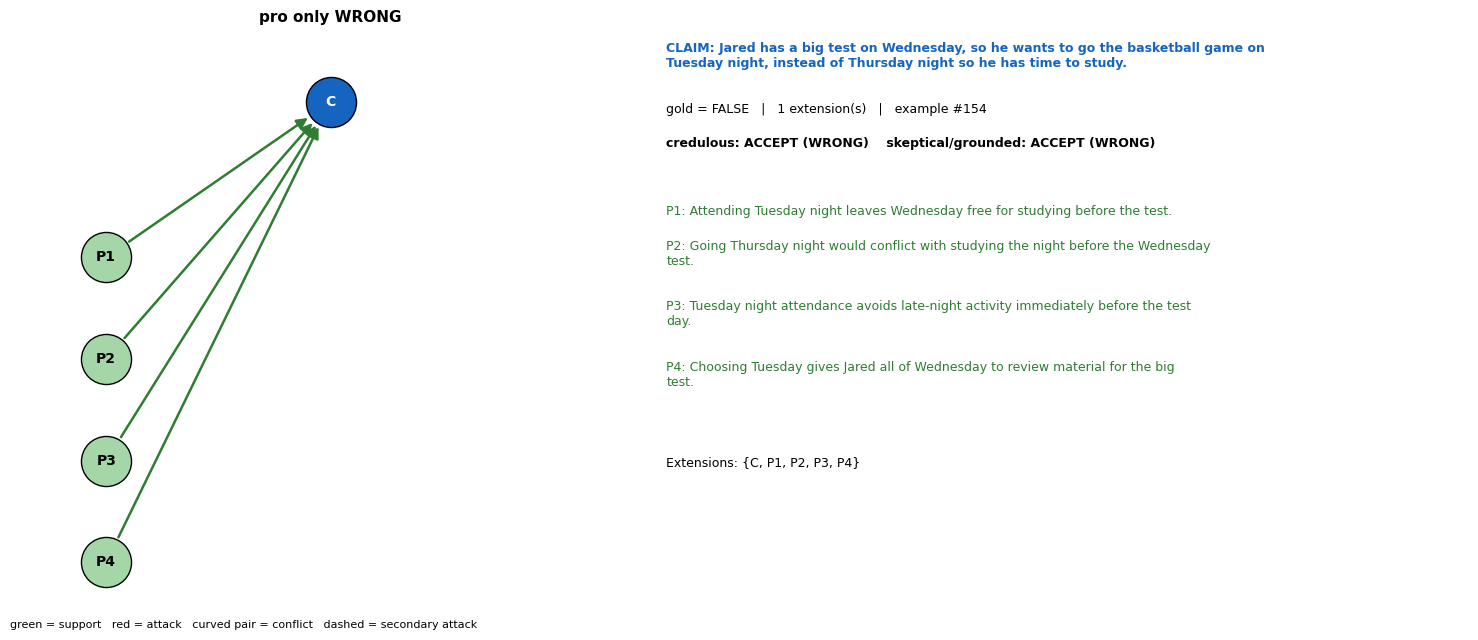

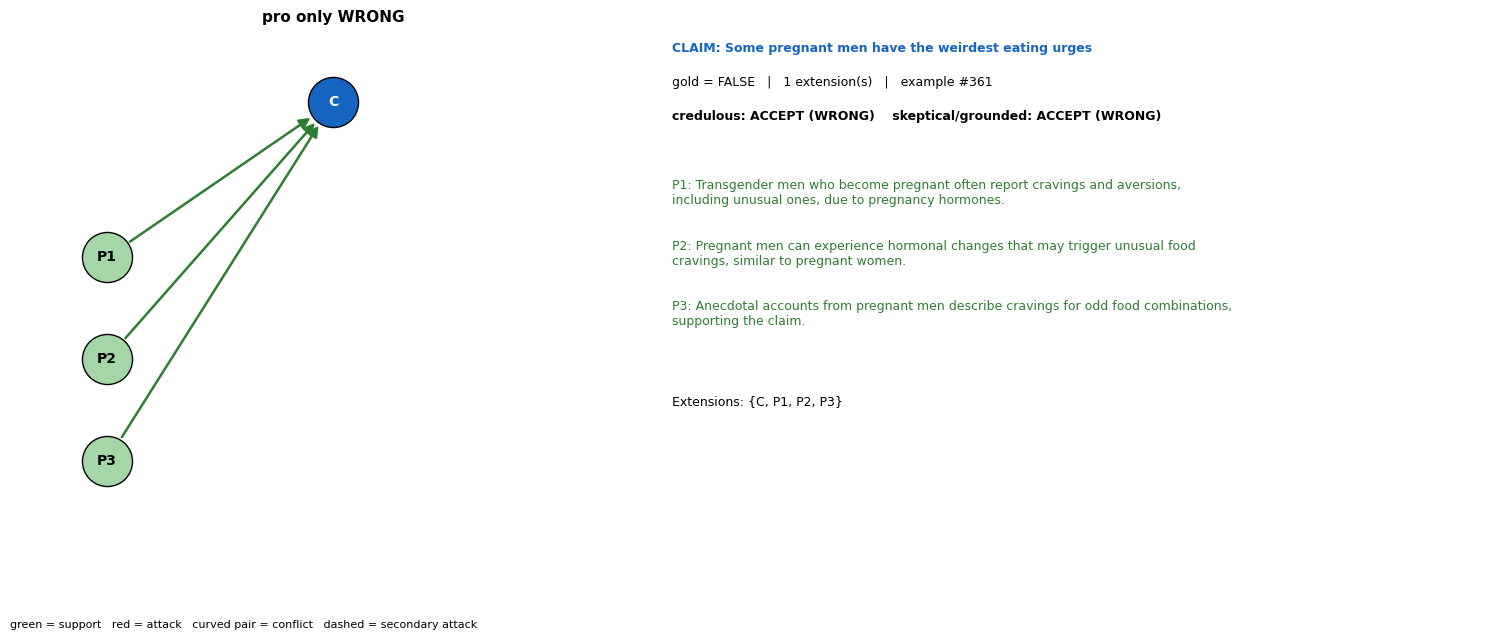

04_con_only_correct  (76 claims in this situation)


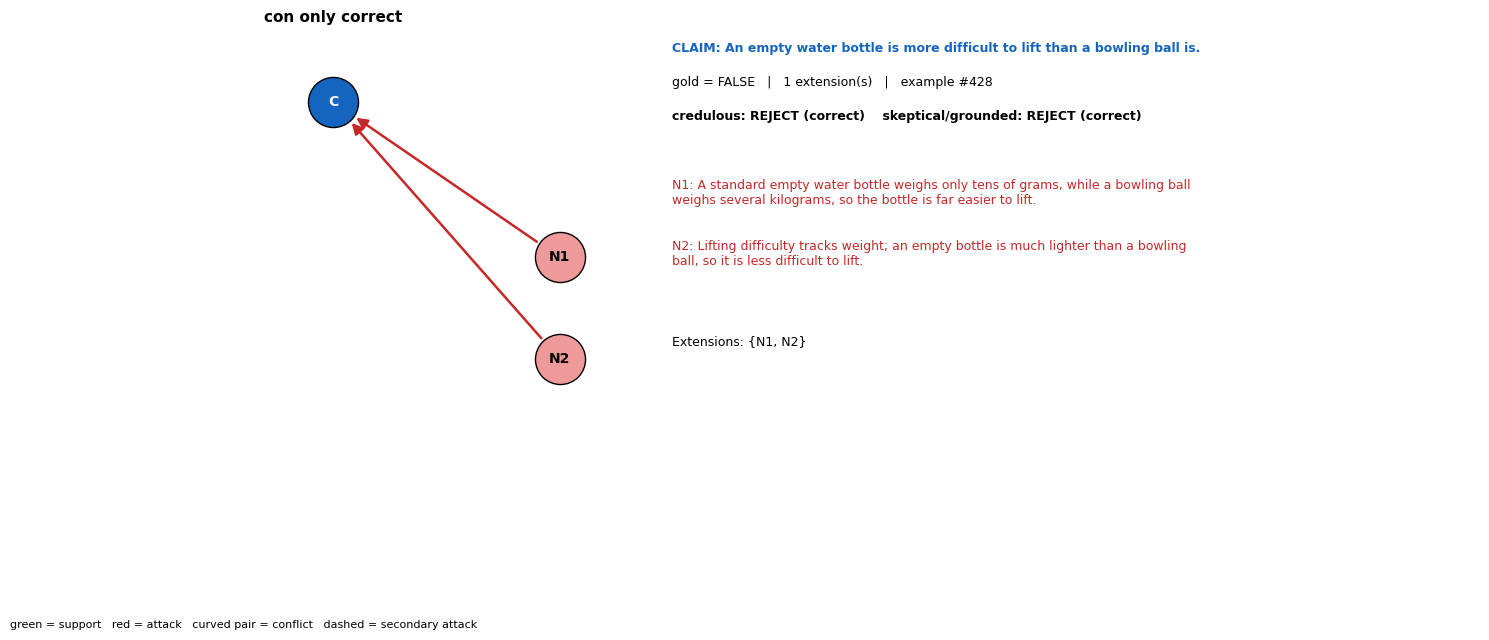

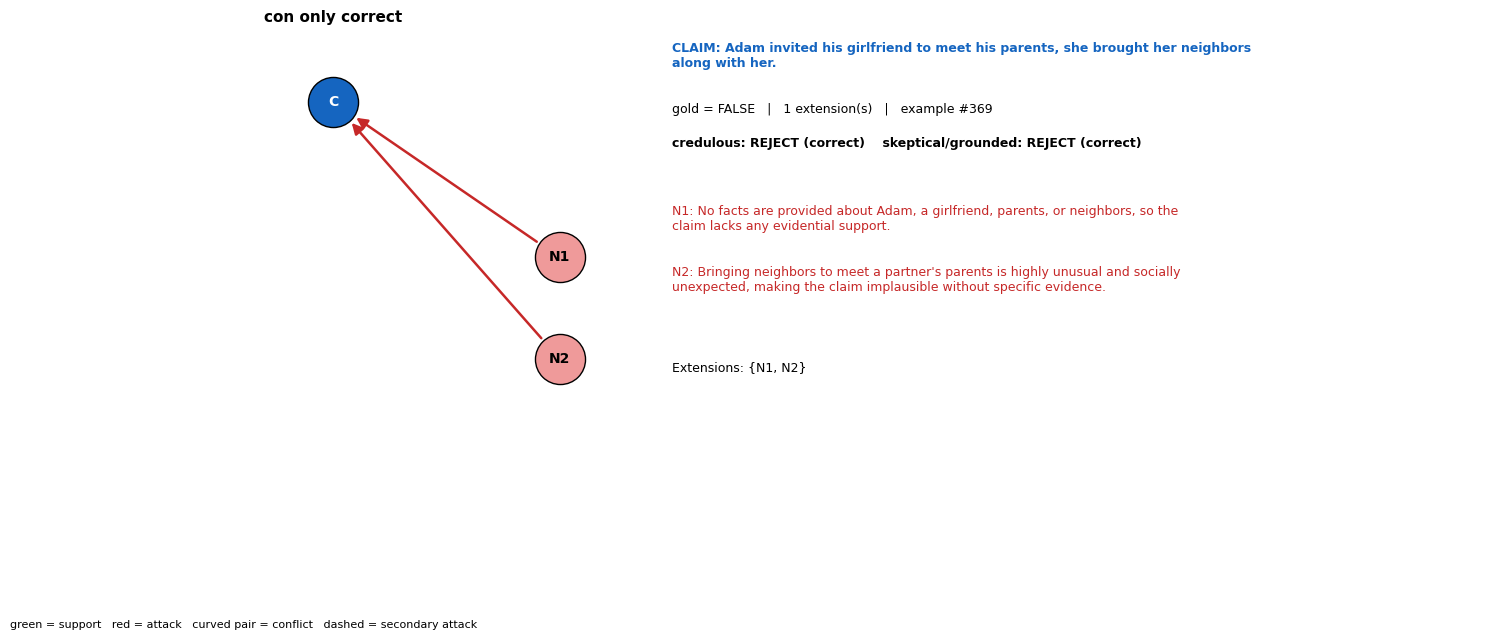

05_con_only_WRONG  (6 claims in this situation)


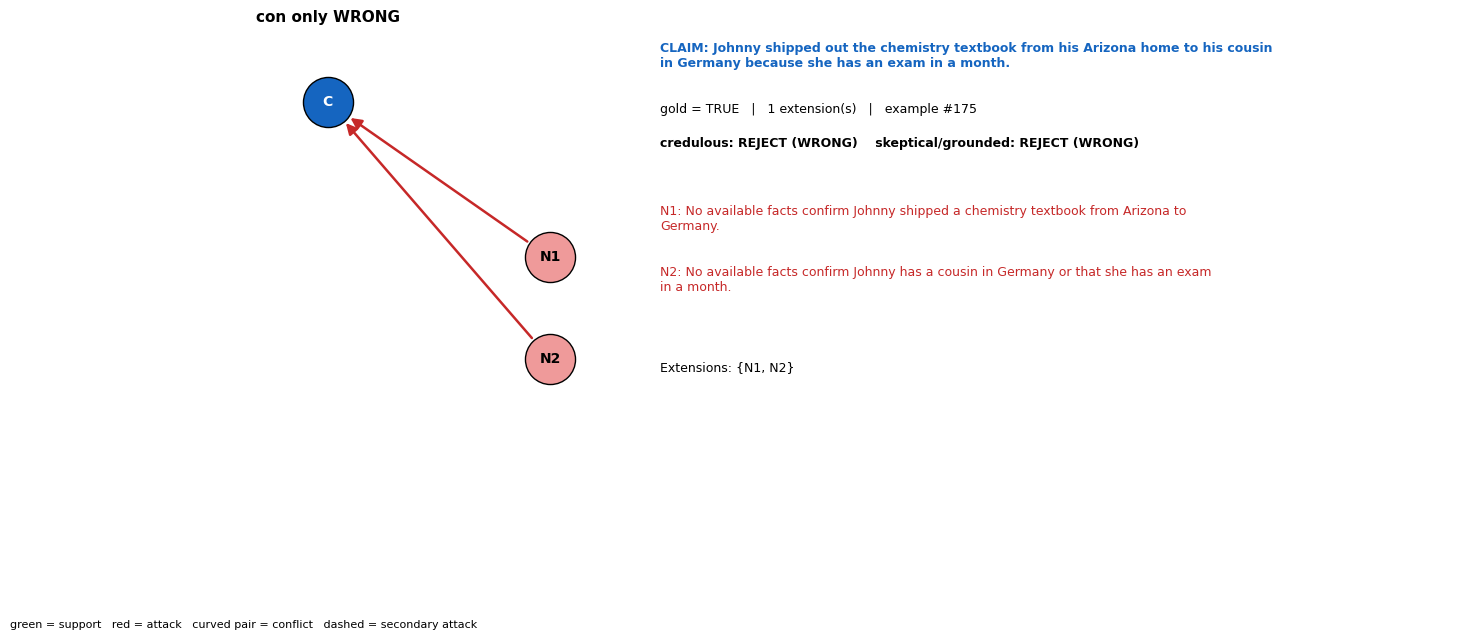

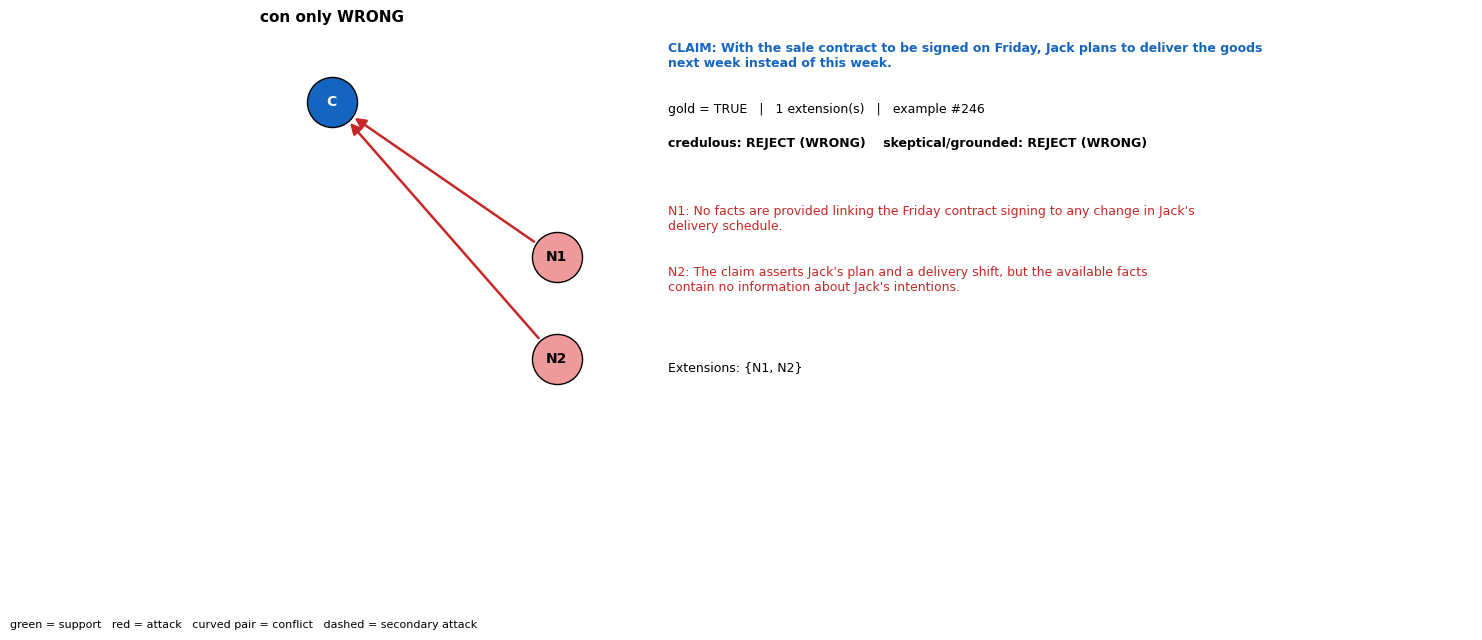

06_pro_and_con_no_pair  (10 claims in this situation)


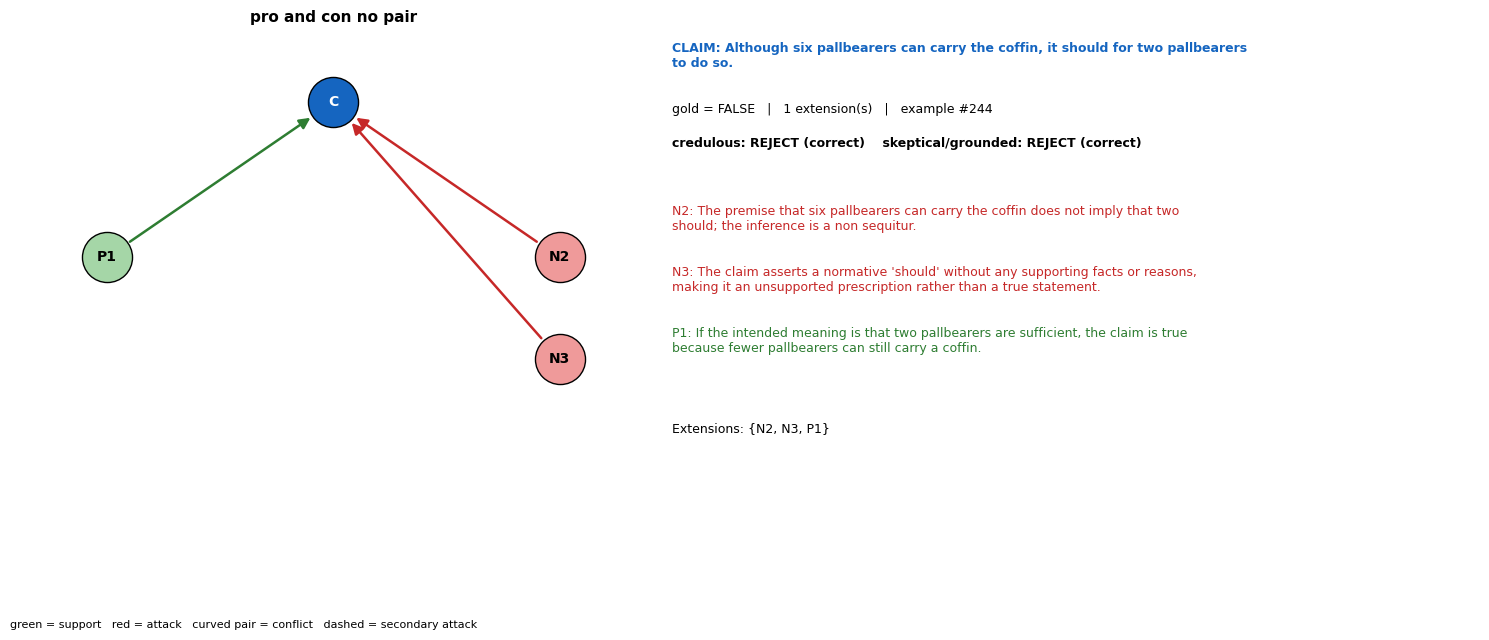

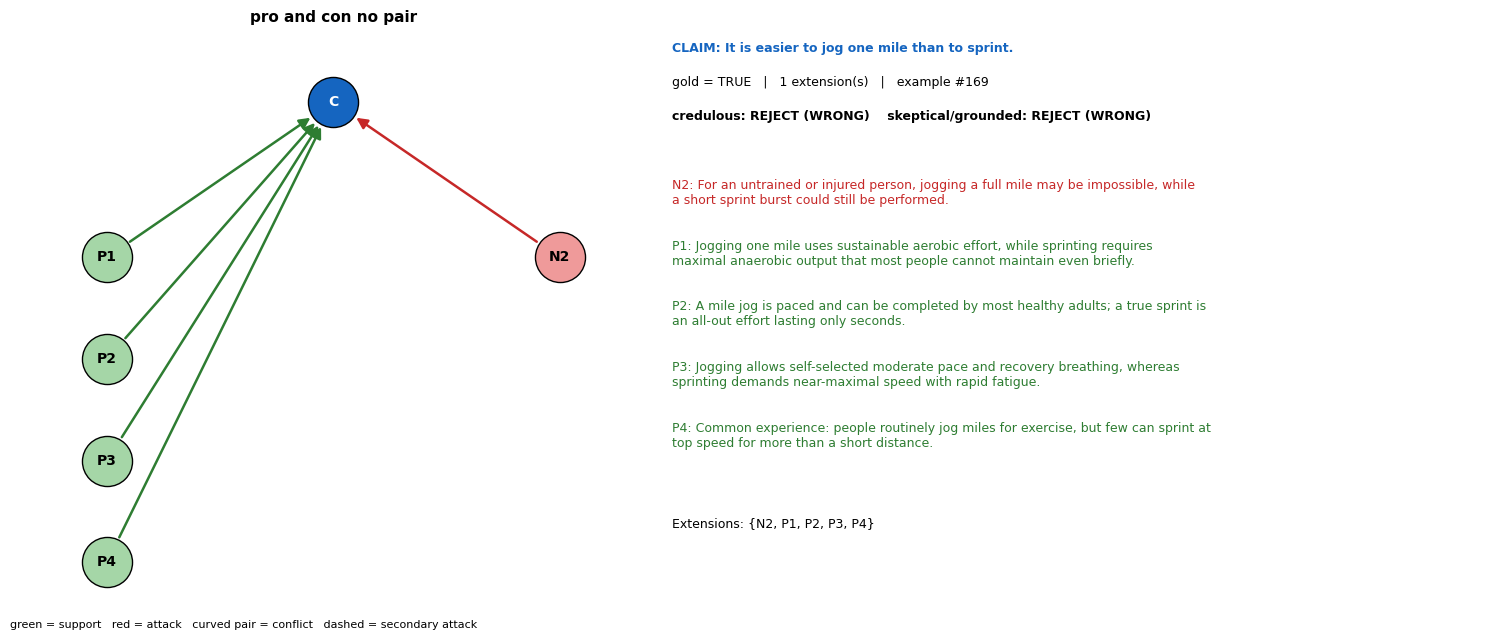

07_pair_direct_attack  (3 claims in this situation)


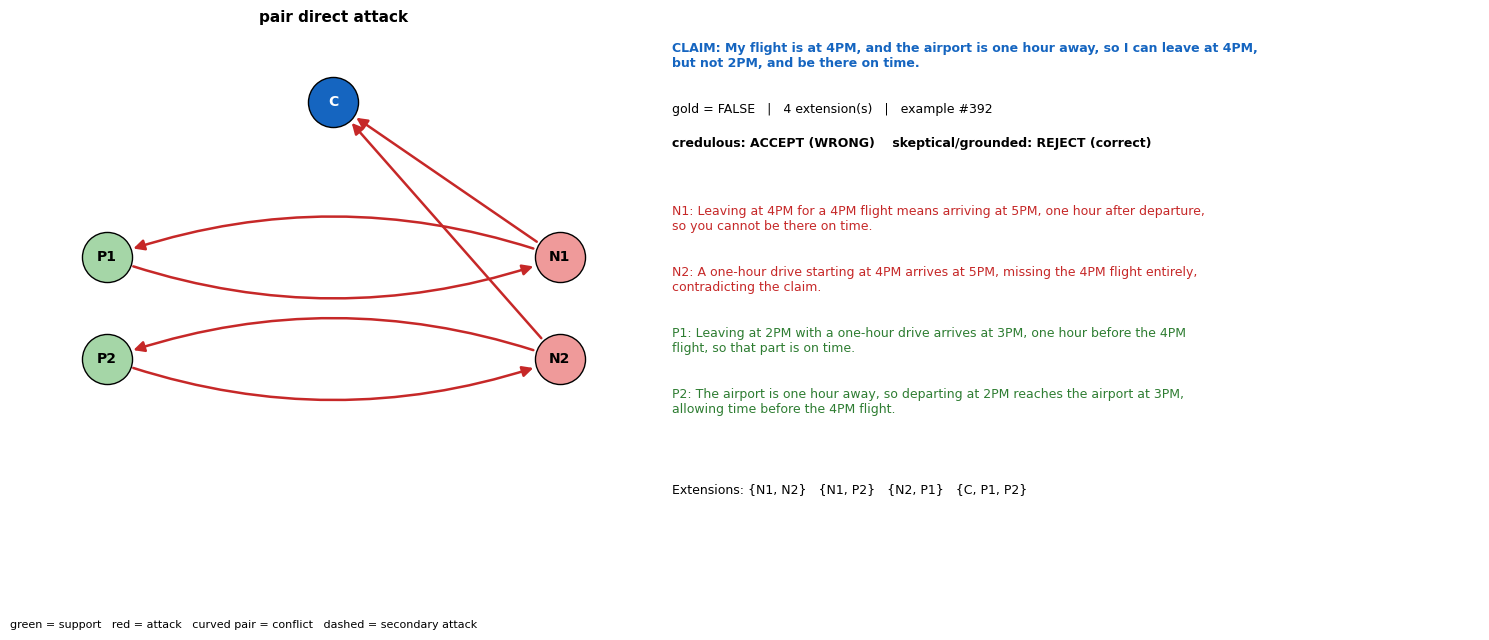

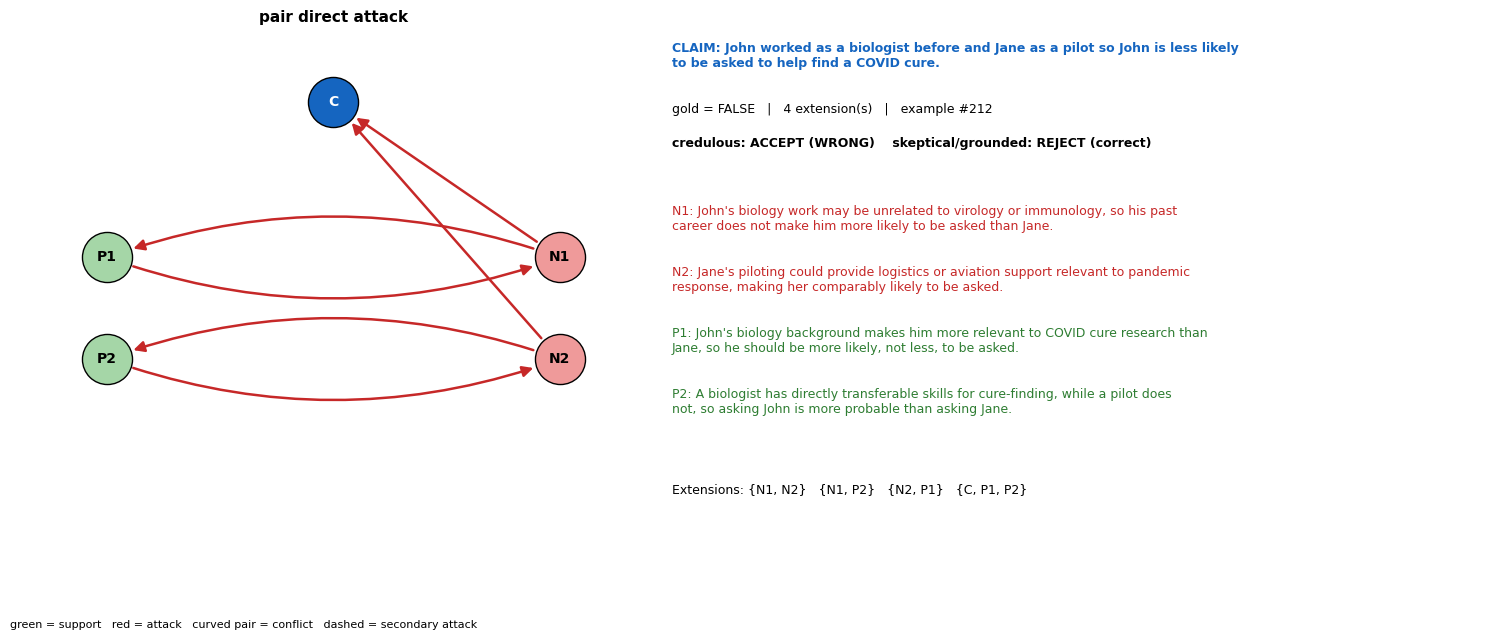

08_pair_secondary_attack  (206 claims in this situation)


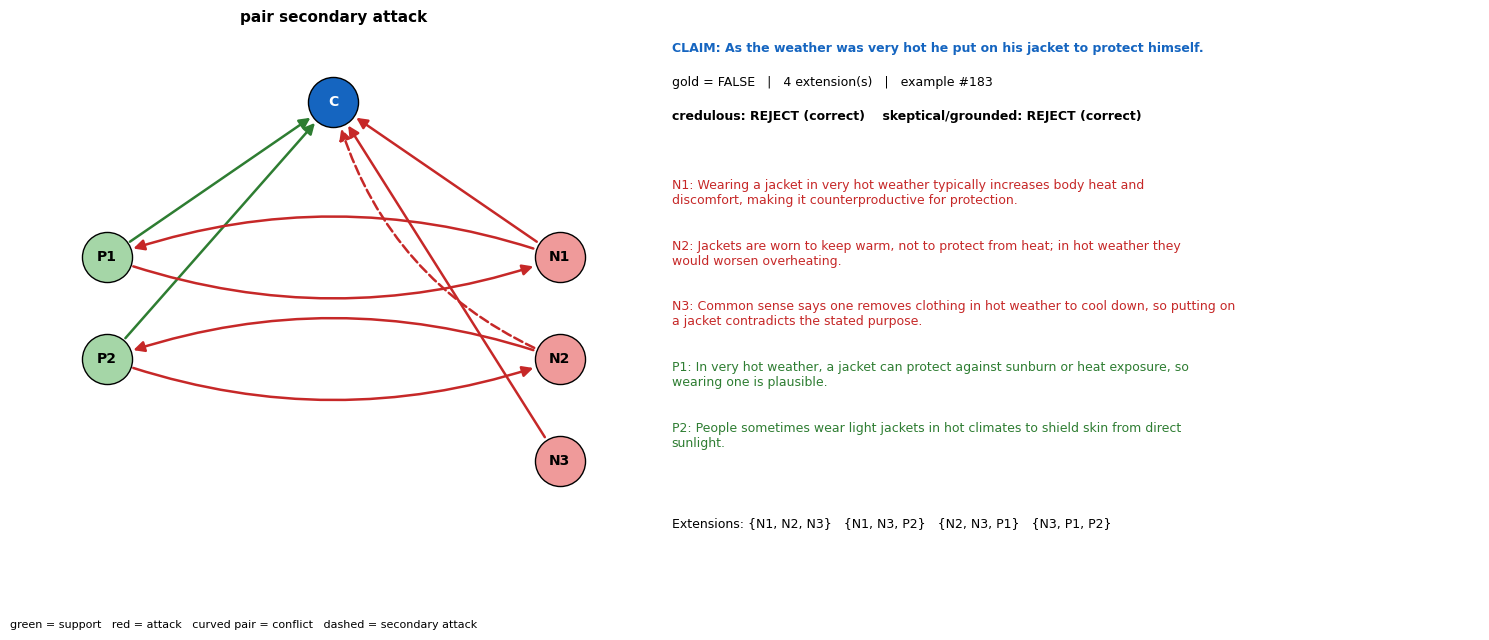

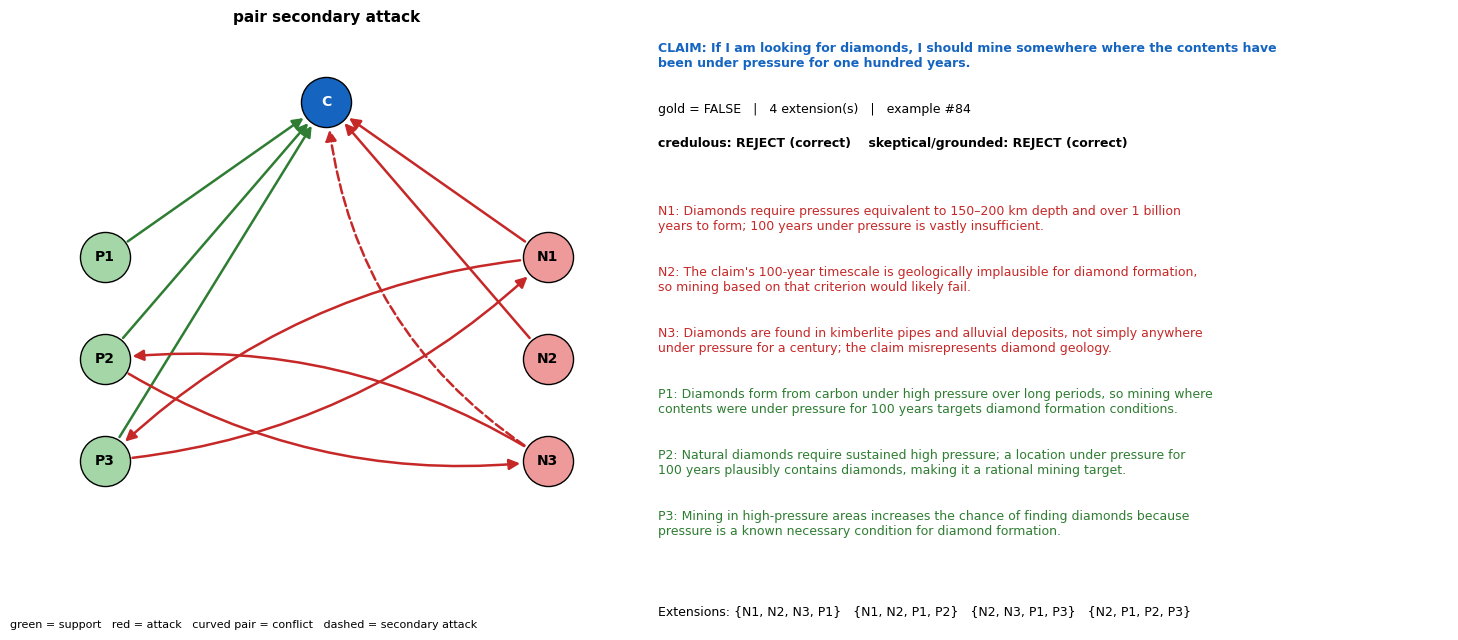

09_rules_disagree_skep_right  (94 claims in this situation)


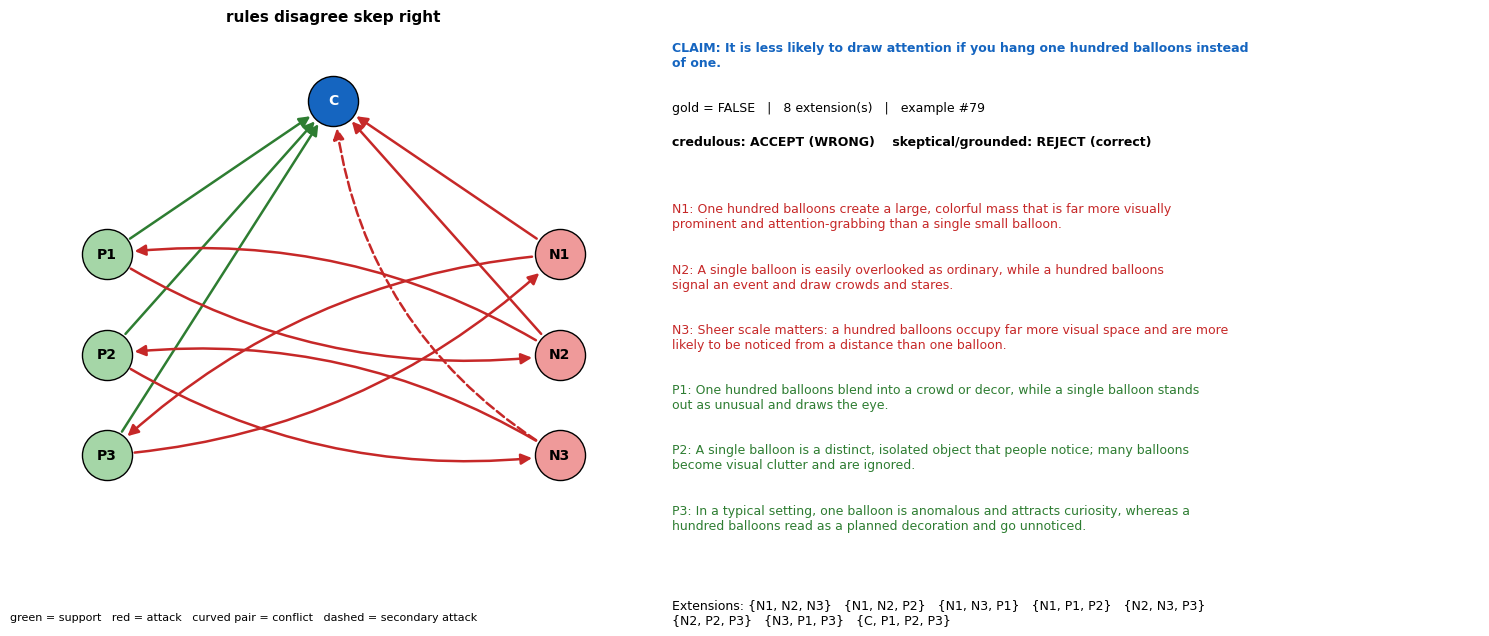

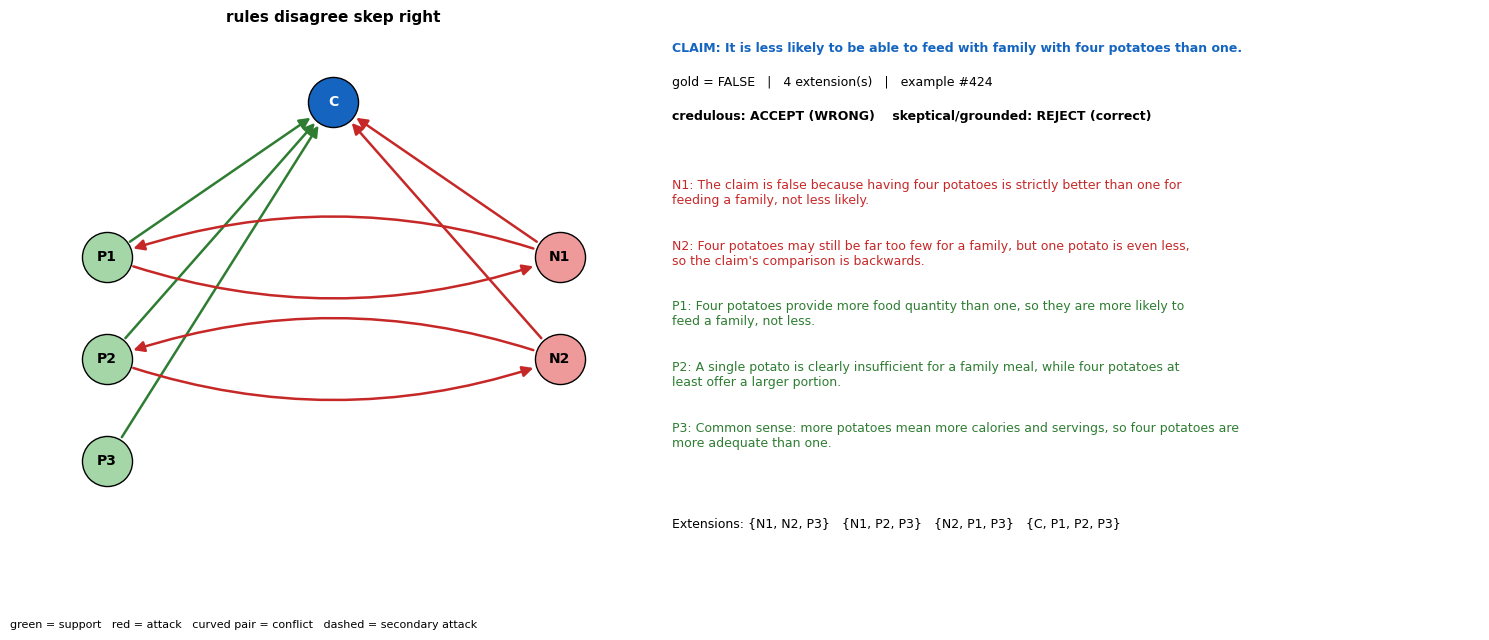

10_rules_disagree_cred_right  (49 claims in this situation)


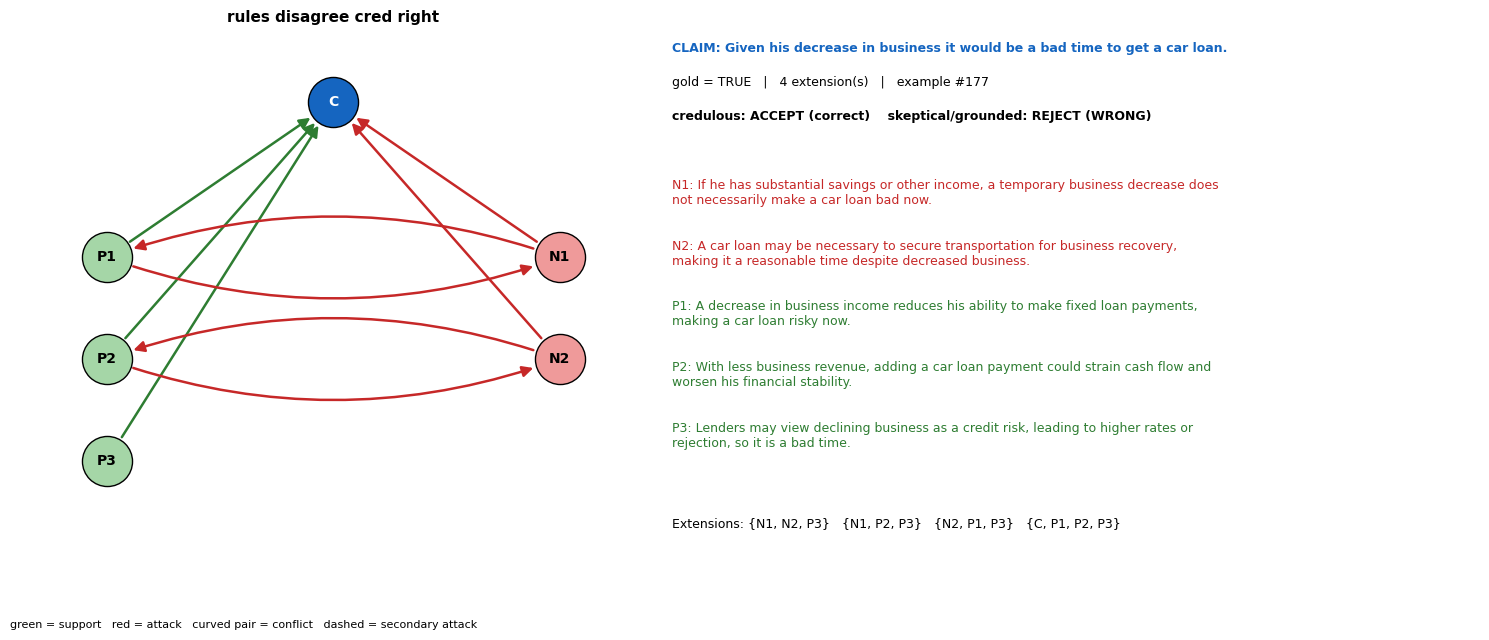

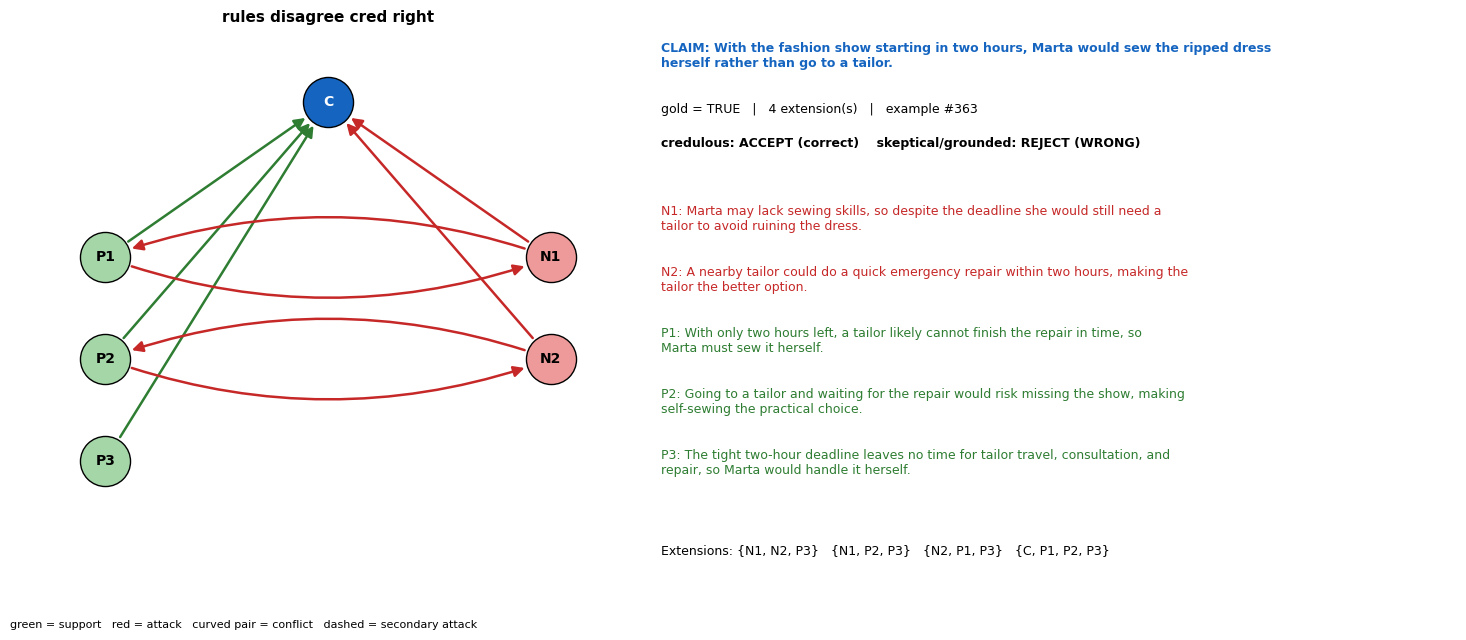

11_largest_framework


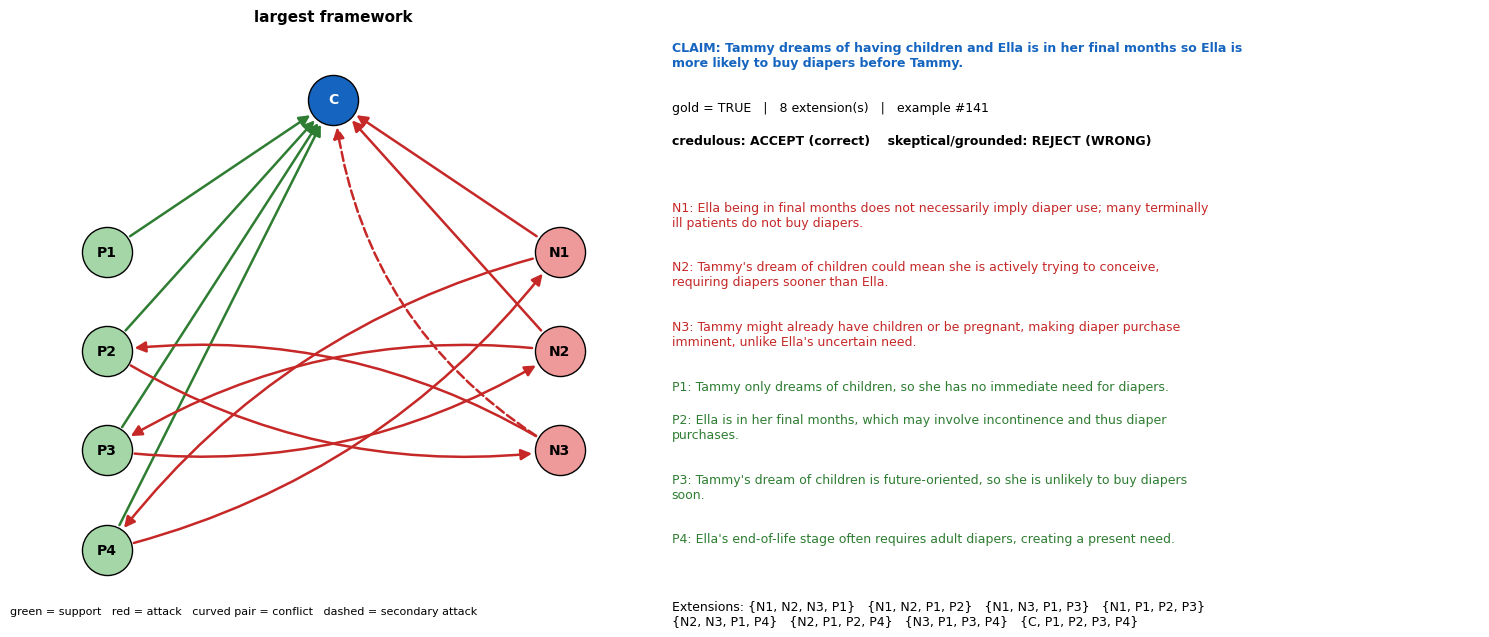

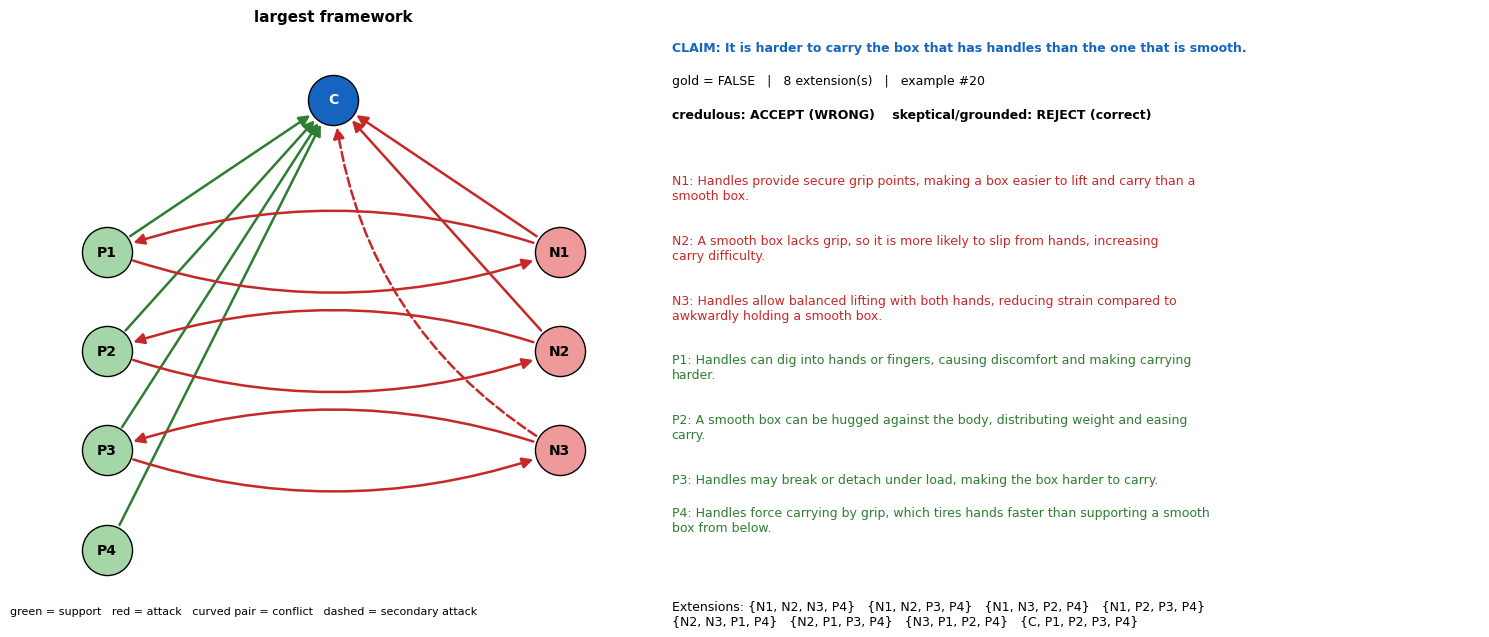


=== how many claims fall in each situation ===
                   situation claims
               01_claim_only     16
         02_pro_only_correct    158
           03_pro_only_WRONG     25
         04_con_only_correct     76
           05_con_only_WRONG      6
      06_pro_and_con_no_pair     10
       07_pair_direct_attack      3
    08_pair_secondary_attack    206
09_rules_disagree_skep_right     94
10_rules_disagree_cred_right     49
        11_largest_framework      -


In [13]:
# ===== CELL 10: diverse example graphs (no API calls) =====
import random, textwrap, shutil
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

N_PER_TYPE = 2
SEED_G = 0
OUT_DIR = Path("/kaggle/working") / f"{RUN_NAME}_graphs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
rng = random.Random(SEED_G)


def info(r):
    att = set(map(tuple, r["effective_attacks"]))
    dec = decide(r["preferred_extensions"], att)
    n_pro = sum(k.startswith("P") for k in r["nodes"])
    n_con = sum(k.startswith("N") for k in r["nodes"])
    return dict(att=att, dec=dec, n_pro=n_pro, n_con=n_con,
                pairs=len(r["selected_conflict_pairs"]),
                sec=len(r["secondary_attacks"]),
                n_ext=len(r["preferred_extensions"]),
                skep_ok=dec["skeptical"] == r["gold"],
                cred_ok=dec["credulous"] == r["gold"])


SITUATIONS = [
    ("01_claim_only",            lambda r, i: i["n_pro"] + i["n_con"] == 0),
    ("02_pro_only_correct",      lambda r, i: i["n_con"] == 0 and i["n_pro"] > 0 and i["skep_ok"]),
    ("03_pro_only_WRONG",        lambda r, i: i["n_con"] == 0 and i["n_pro"] > 0 and not i["skep_ok"]),
    ("04_con_only_correct",      lambda r, i: i["n_pro"] == 0 and i["n_con"] > 0 and i["skep_ok"]),
    ("05_con_only_WRONG",        lambda r, i: i["n_pro"] == 0 and i["n_con"] > 0 and not i["skep_ok"]),
    ("06_pro_and_con_no_pair",   lambda r, i: i["n_pro"] > 0 and i["n_con"] > 0 and i["pairs"] == 0),
    ("07_pair_direct_attack",    lambda r, i: i["pairs"] > 0 and i["sec"] == 0),
    ("08_pair_secondary_attack", lambda r, i: i["pairs"] > 0 and i["sec"] > 0),
    ("09_rules_disagree_skep_right", lambda r, i: i["dec"]["credulous"] != i["dec"]["skeptical"] and i["skep_ok"]),
    ("10_rules_disagree_cred_right", lambda r, i: i["dec"]["credulous"] != i["dec"]["skeptical"] and i["cred_ok"]),
    ("11_largest_framework",     None),
]


def pos_of(nodes):
    pro = sorted(k for k in nodes if k.startswith("P"))
    con = sorted(k for k in nodes if k.startswith("N"))
    pos = {"CLAIM": (0.5, 0.88)}
    for j, k in enumerate(pro):
        pos[k] = (0.15, 0.62 - j * 0.17)
    for j, k in enumerate(con):
        pos[k] = (0.85, 0.62 - j * 0.17)
    return pos


def arrow(ax, a, b, color, rad=0.0, ls="-"):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=16,
                                 color=color, lw=1.8, ls=ls, shrinkA=20, shrinkB=20,
                                 connectionstyle=f"arc3,rad={rad}", zorder=2))


def draw(r, situation, fname):
    i = info(r)
    nodes, pos = r["nodes"], pos_of(r["nodes"])
    sup = {tuple(e) for e in r["supports"]}
    direct = {tuple(e) for e in r["direct_attacks"]}
    second = {tuple(e) for e in r["secondary_attacks"]} - direct
    fig, (ax, tx) = plt.subplots(1, 2, figsize=(15, 6.5),
                                 gridspec_kw={"width_ratios": [1, 1.25]})
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    for a, b in sup:
        arrow(ax, pos[a], pos[b], "#2e7d32")
    for a, b in direct:
        arrow(ax, pos[a], pos[b], "#c62828", rad=0.18 if (b, a) in direct else 0.0)
    for a, b in second:
        arrow(ax, pos[a], pos[b], "#c62828", rad=-0.25, ls="--")
    colors = {"CLAIM": "#1565c0", "PRO": "#a5d6a7", "CON": "#ef9a9a"}
    for k, (x, y) in pos.items():
        ax.scatter(x, y, s=1300, c=colors[nodes[k]["role"]], edgecolors="black", zorder=3)
        ax.text(x, y, "C" if k == "CLAIM" else k, ha="center", va="center", zorder=4,
                fontsize=10, fontweight="bold", color="white" if k == "CLAIM" else "black")
    ax.text(0, 0.0, "green = support   red = attack   curved pair = conflict   "
            "dashed = secondary attack", fontsize=8)
    ax.set_title(situation.split("_", 1)[1].replace("_", " "), fontsize=11, fontweight="bold")
    tx.axis("off")
    yes = lambda v: "ACCEPT" if v else "REJECT"
    mark = lambda ok: "correct" if ok else "WRONG"
    lines = [("CLAIM: " + r["claim"], "#1565c0", "bold"),
             (f"gold = {'TRUE' if r['gold'] else 'FALSE'}   |   "
              f"{i['n_ext']} extension(s)   |   example #{r['example_index']}", "black", "normal"),
             (f"credulous: {yes(i['dec']['credulous'])} ({mark(i['cred_ok'])})    "
              f"skeptical/grounded: {yes(i['dec']['skeptical'])} ({mark(i['skep_ok'])})",
              "black", "bold"),
             ("", "black", "normal")]
    for k in sorted(nodes):
        if k == "CLAIM":
            continue
        col = "#2e7d32" if k.startswith("P") else "#c62828"
        lines.append((f"{k}: {nodes[k]['text']}", col, "normal"))
    lines.append(("", "black", "normal"))
    lines.append(("Extensions: " + "   ".join("{" + ", ".join(
        "C" if a == "CLAIM" else a for a in e) + "}" for e in r["preferred_extensions"]),
        "black", "normal"))
    y = 0.98
    for text, col, w in lines:
        wrapped = textwrap.fill(text, 85) if text else " "
        tx.text(0, y, wrapped, fontsize=9, color=col, fontweight=w, va="top",
                transform=tx.transAxes)
        y -= 0.045 * (wrapped.count("\n") + 1) + 0.012
    plt.tight_layout()
    plt.savefig(fname, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


summary = []
for name, test in SITUATIONS:
    if test is None:
        pool = sorted(results, key=lambda r: -len(r["nodes"]))[:10]
    else:
        pool = [r for r in results if test(r, info(r))]
    summary.append({"situation": name, "claims": len(pool) if test else "-"})
    print("=" * 90)
    print(f"{name}  ({len(pool)} claims in this situation)" if test else name)
    if not pool:
        print("   no claim in this situation")
        continue
    for r in rng.sample(pool, min(N_PER_TYPE, len(pool))):
        draw(r, name, OUT_DIR / f"{name}_ex{r['example_index']}.png")

print("\n=== how many claims fall in each situation ===")
print(pd.DataFrame(summary).to_string(index=False))
for f in OUT_DIR.glob("*.png"):
    shutil.copy(f, Path("/kaggle/working") / f"{RUN_NAME}_{f.name}")